# Breaking a 7-bit ECDLP with Shor's algorithm in Qiskit

**Target:** reduce the elliptic-curve discrete-log problem (ECDLP) to a period-finding problem and solve it with Shor's algorithm for a 7-bit curve.

**Setup:** $E:\; y^2 = x^3 + 7 \pmod{127}$ (same equation as Bitcoin's secp256k1, just over a 7-bit prime instead of a 256-bit one).

**Roadmap**
1. Elliptic-curve arithmetic over $\mathbb{F}_{127}$ and the group order $n$
2. Pick a generator $P$, a secret 7-bit key $k$, publish $Q = kP$
3. Reduction: $f(a,b) = aP + bQ$ is periodic in **two** variables, and its period encodes $k$
4. The Shor circuit: superposition → oracle $|a,b,\mathcal{O}\rangle \mapsto |a,b,aP+bQ\rangle$ → QFT on both registers → measure
5. Simulate with Qiskit Aer
6. Classical post-processing: turn measured $(u,v)$ into $k = v\,u^{-1} \bmod n$ and verify $kP = Q$

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.colors import LinearSegmentedColormap
from collections import Counter
from math import floor, ceil

import qiskit, qiskit_aer
from qiskit import QuantumCircuit, QuantumRegister, ClassicalRegister, transpile
from qiskit.circuit.library import QFTGate, UnitaryGate
from qiskit_aer import AerSimulator

print("qiskit", qiskit.__version__, "| qiskit-aer", qiskit_aer.__version__)

# plot styling: light surface, recessive axes, one blue ramp for magnitude
BLUE, ORANGE, AQUA, GRAY = "#2a78d6", "#eb6834", "#1baf7a", "#b4b2a7"
SEQ_BLUE = LinearSegmentedColormap.from_list(
    "seq_blue", ["#fcfcfb", "#cde2fb", "#86b6ef", "#3987e5", "#1c5cab", "#0d366b"])
plt.rcParams.update({
    "figure.facecolor": "#fcfcfb", "axes.facecolor": "#fcfcfb",
    "axes.edgecolor": "#c3c2b7", "axes.linewidth": 0.8,
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.titlesize": 12, "axes.labelsize": 10, "font.size": 10,
    "xtick.color": "#5f5e58", "ytick.color": "#5f5e58",
})

qiskit 2.6.2 | qiskit-aer 0.18.2


## 1. The curve $y^2 = x^3 + 7$ over $\mathbb{F}_{127}$

Points are pairs $(x, y)$ with $x, y \in \{0,\dots,126\}$ satisfying the equation, plus a **point at infinity** $\mathcal{O}$ that acts as the identity. The group law (chord-and-tangent) for $P_1 + P_2 = P_3$:

$$\lambda = \begin{cases} \dfrac{y_2 - y_1}{x_2 - x_1} & P_1 \ne P_2 \\[2mm] \dfrac{3x_1^2 + a}{2y_1} & P_1 = P_2 \end{cases}
\qquad x_3 = \lambda^2 - x_1 - x_2, \qquad y_3 = \lambda(x_1 - x_3) - y_1 \pmod p$$

Scalar multiplication $kP = P + \dots + P$ uses double-and-add, so it takes $O(\log k)$ group operations.

In [2]:
p = 127                 # 7-bit prime: 127 = 0b1111111
A_COEF, B_COEF = 0, 7   # y^2 = x^3 + A x + B
O = None                # point at infinity (group identity)

def on_curve(P):
    if P is O:
        return True
    x, y = P
    return (y * y - (x**3 + A_COEF * x + B_COEF)) % p == 0

def ec_neg(P):
    return O if P is O else (P[0], (-P[1]) % p)

def ec_add(P1, P2):
    if P1 is O: return P2
    if P2 is O: return P1
    x1, y1 = P1
    x2, y2 = P2
    if x1 == x2 and (y1 + y2) % p == 0:            # P + (-P) = O
        return O
    if P1 == P2:                                     # tangent (doubling)
        lam = (3 * x1 * x1 + A_COEF) * pow(2 * y1, -1, p) % p
    else:                                            # chord
        lam = (y2 - y1) * pow(x2 - x1, -1, p) % p
    x3 = (lam * lam - x1 - x2) % p
    y3 = (lam * (x1 - x3) - y1) % p
    return (x3, y3)

def ec_mul(k, P):
    # double-and-add
    R = O
    while k > 0:
        if k & 1:
            R = ec_add(R, P)
        P = ec_add(P, P)
        k >>= 1
    return R

In [3]:
# enumerate every point of E(F_127)
points = [O] + [(x, y) for x in range(p) for y in range(p) if on_curve((x, y))]
n = len(points)

is_prime = n > 1 and all(n % d for d in range(2, int(n**0.5) + 1))
print(f"#E(F_{p}) = n = {n}   (prime: {is_prime})")
print(f"Hasse bound check: |n - (p+1)| = {abs(n - (p + 1))} <= 2*sqrt(p) = {2 * p**0.5:.1f}")

#E(F_127) = n = 127   (prime: True)
Hasse bound check: |n - (p+1)| = 1 <= 2*sqrt(p) = 22.5


The group has **$n = 127$ elements, a prime**. So $E(\mathbb{F}_{127})$ is cyclic and *every* point other than $\mathcal{O}$ is a generator of the whole group. That also means scalars live in $\mathbb{Z}_{127}$, i.e. they are 7-bit numbers, and we can use 7-qubit exponent registers.

*Side note:* $n = p$ makes this an "anomalous" curve, which is classically weak (Smart's attack). That is irrelevant for this exercise. We only care that the group is small enough to simulate.

## 2. Generator $P$, secret key $k$, public key $Q = kP$

In [4]:
def point_order(P):
    R, i = P, 1
    while R is not O:
        R = ec_add(R, P)
        i += 1
    return i

P = (1, 32)                         # generator point
assert on_curve(P)
print(f"generator P = {P},  order(P) = {point_order(P)}")

k_secret = 0b1100101                # = 101, the 7-bit private key
assert k_secret.bit_length() == 7 and 0 < k_secret < n
Q = ec_mul(k_secret, P)             # public key

print(f"private key k = {k_secret} = 0b{k_secret:07b}")
print(f"public key  Q = kP = {Q}")

generator P = (1, 32),  order(P) = 127
private key k = 101 = 0b1100101
public key  Q = kP = (41, 27)


From here on, the quantum attack only uses **public** information: $p$, the curve, $n$, $P$ and $Q$. `k_secret` is touched again only (a) in one cell that illustrates the periodicity and (b) at the very end to check the answer.

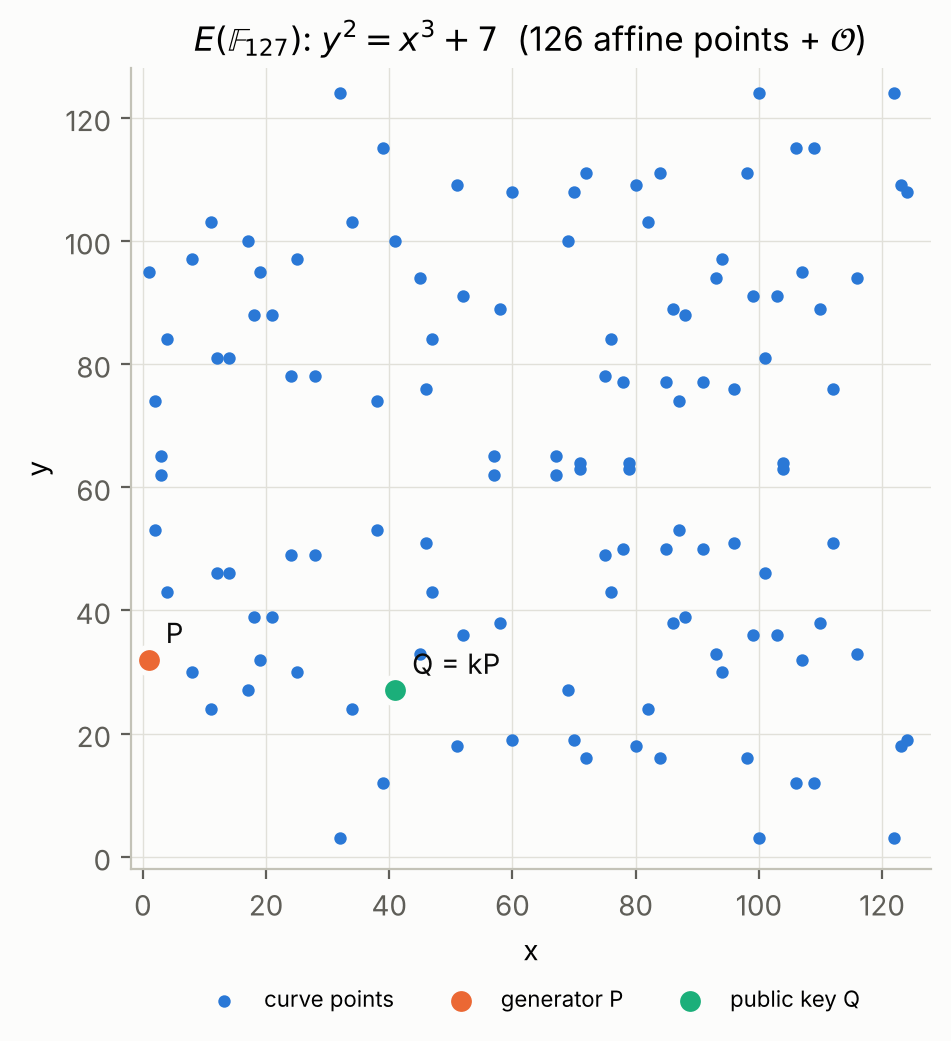

In [5]:
xs, ys = zip(*points[1:])
fig, ax = plt.subplots(figsize=(5.2, 5.2))
ax.scatter(xs, ys, s=12, color=BLUE, label="curve points", zorder=2)
ax.scatter(*P, s=90, color=ORANGE, edgecolor="#fcfcfb", linewidth=2, zorder=3, label="generator P")
ax.scatter(*Q, s=90, color=AQUA, edgecolor="#fcfcfb", linewidth=2, zorder=3, label="public key Q")
ax.annotate("P", P, xytext=(6, 6), textcoords="offset points", color="#0b0b0b")
ax.annotate("Q = kP", Q, xytext=(6, 6), textcoords="offset points", color="#0b0b0b")
ax.set(xlim=(-2, 128), ylim=(-2, 128), xlabel="x", ylabel="y",
       title=r"$E(\mathbb{F}_{127})$: $y^2 = x^3 + 7$  (126 affine points + $\mathcal{O}$)")
ax.set_aspect("equal")
ax.grid(color="#e1e0d9", linewidth=0.5, zorder=0)
ax.legend(loc="upper center", bbox_to_anchor=(0.5, -0.12), fontsize=8, frameon=False, ncol=3)
plt.show()

## 3. Reduction: ECDLP → two-parameter period finding

Define
$$f(a, b) = aP + bQ, \qquad a, b \in \mathbb{Z}_n .$$

Because $Q = kP$,
$$f(a,b) = aP + b(kP) = (a + kb)\,P .$$

So $f(a,b) = f(a',b')$ exactly when $a + kb \equiv a' + kb' \pmod n$. In other words $f$ is constant on the cosets of the **hidden lattice**
$$L = \{(a,b) : a + kb \equiv 0 \pmod n\} = \operatorname{span}\{(n, 0),\ (-k, 1)\}.$$

The **period vector is $(-k, 1)$**: $f(a - k,\, b + 1) = f(a, b)$. Compare with RSA/factoring, where $g(x) = a^x \bmod N$ has a single period $r$. Here the period is a direction in a 2-D grid, and its slope is the secret.

**Why the QFT finds it.** If we prepare $\sum_{a,b} |a\rangle|b\rangle|f(a,b)\rangle$ and look at one value of $f$, the first two registers collapse to a coset $\{(a,b): a + kb \equiv c\}$. Fourier transforming both registers gives amplitude
$$\sum_{b} \omega^{u(c - kb) + vb} = \omega^{uc} \sum_b \omega^{b(v - ku)}, \qquad \omega = e^{2\pi i/n},$$
which is non-zero only when $v \equiv k\,u \pmod n$. Measuring any $(u, v)$ with $u \ne 0$ therefore gives
$$\boxed{k \equiv v \cdot u^{-1} \pmod n.}$$

In [6]:
# illustration only: check the period vector (-k, 1) using the secret
def f(a, b):
    return ec_add(ec_mul(a, P), ec_mul(b, Q))

rng = np.random.default_rng(0)
for _ in range(4):
    a, b = (int(x) for x in rng.integers(0, n, 2))
    a2, b2 = (a - k_secret) % n, (b + 1) % n
    print(f"f({a:3d},{b:3d}) = {f(a, b)}    f({a2:3d},{b2:3d}) = {f(a2, b2)}")

f(108, 80) = (98, 111)    f(  7, 81) = (98, 111)
f( 64, 34) = (124, 19)    f( 90, 35) = (124, 19)
f( 39,  5) = (12, 46)    f( 65,  6) = (12, 46)
f(  9,  2) = (46, 51)    f( 35,  3) = (46, 51)


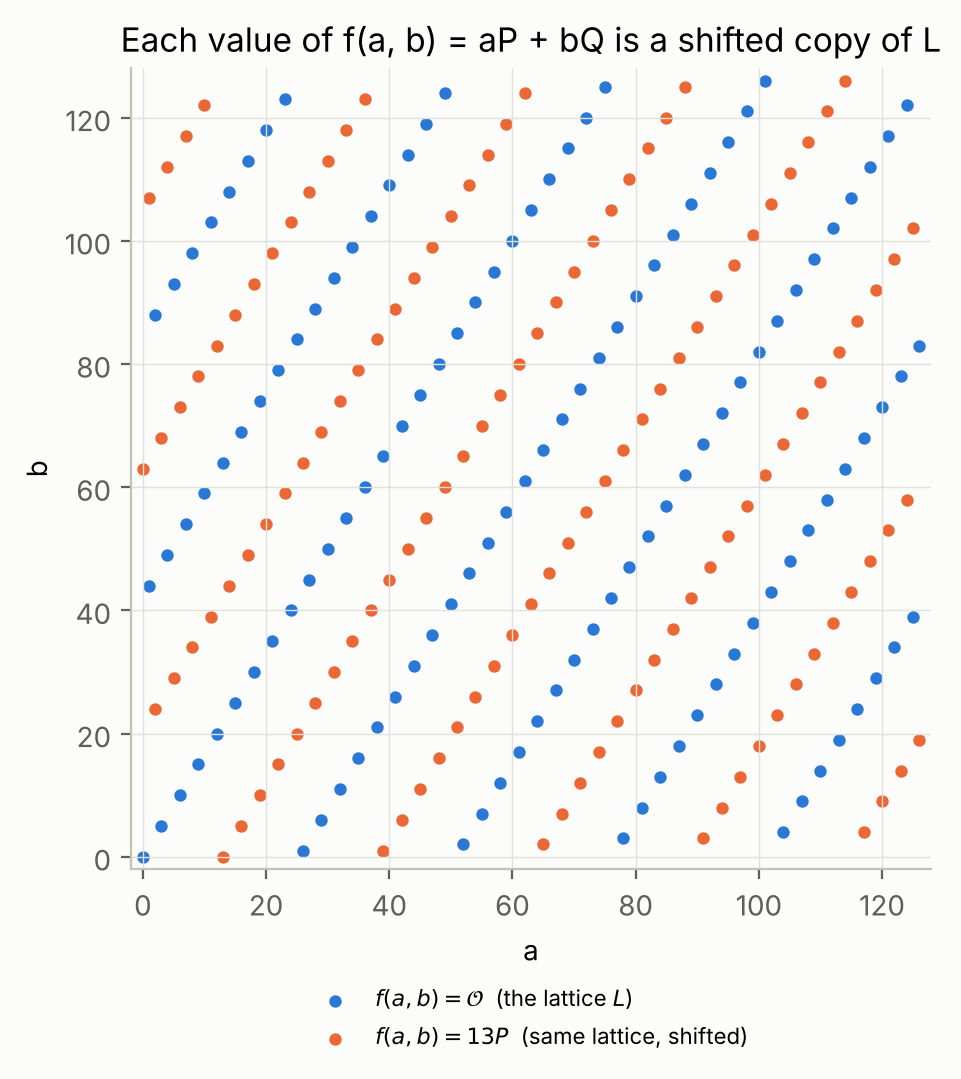

each level set has 127 points (= n): f is n-to-1 on the n x n grid


In [7]:
# level sets of f over the full grid Z_127 x Z_127
aP = [ec_mul(a, P) for a in range(n)]
bQ = [ec_mul(b, Q) for b in range(n)]
F = [[ec_add(aP[a], bQ[b]) for b in range(n)] for a in range(n)]

level_O = [(a, b) for a in range(n) for b in range(n) if F[a][b] is O]
R13 = ec_mul(13, P)
level_R = [(a, b) for a in range(n) for b in range(n) if F[a][b] == R13]

fig, ax = plt.subplots(figsize=(5.2, 5.2))
ax.scatter(*zip(*level_O), s=12, color=BLUE, label=r"$f(a,b)=\mathcal{O}$  (the lattice $L$)")
ax.scatter(*zip(*level_R), s=12, color=ORANGE, label=r"$f(a,b)=13P$  (same lattice, shifted)")
ax.set(xlim=(-2, 128), ylim=(-2, 128), xlabel="a", ylabel="b",
       title="Each value of f(a, b) = aP + bQ is a shifted copy of L")
ax.set_aspect("equal")
ax.grid(color="#e1e0d9", linewidth=0.5, zorder=0)
ax.legend(loc="upper center", bbox_to_anchor=(0.5, -0.12), fontsize=8, frameon=False, ncol=1)
plt.show()
print(f"each level set has {len(level_O)} points (= n): f is n-to-1 on the n x n grid")

## 4. The quantum circuit

**Registers**
| register | qubits | holds |
|---|---|---|
| `a` | 7 | exponent $a$, in uniform superposition over $0..127$ |
| `b` | 7 | exponent $b$, in uniform superposition over $0..127$ |
| `point` | 7 | a curve point, encoded as its index in the public list `points` ($\mathcal{O} \leftrightarrow |0\rangle$) |

Total: **21 qubits**. The QFT register size is $N = 2^7 = 128$, which is almost exactly $n = 127$. That near-match is what makes the QFT over $\mathbb{Z}_{128}$ a good stand-in for the ideal QFT over $\mathbb{Z}_{127}$.

**Oracle** $U_f|a\rangle|b\rangle|\mathcal{O}\rangle = |a\rangle|b\rangle|aP + bQ\rangle$. Writing $a = \sum_i a_i 2^i$ and $b = \sum_j b_j 2^j$:
$$aP + bQ = \sum_i a_i\,(2^iP) + \sum_j b_j\,(2^jQ).$$
So $U_f$ is 14 **controlled "add a fixed point $R$" gates** with $R \in \{2^iP\} \cup \{2^jQ\}$, all precomputed classically from public data. This is the exact analogue of the controlled multiplications by $a^{2^i} \bmod N$ in Shor's factoring circuit.

Adding a fixed point $R$ is a bijection on the group ($X \mapsto X + R$, inverse $X \mapsto X - R$), so on the `point` register it is a **permutation matrix**, hence unitary. Basis state $|127\rangle$ is not a curve point and is left fixed.

**Circuit:** $H^{\otimes 7} \otimes H^{\otimes 7}$ → 14 controlled point-additions → $\mathrm{QFT}_{128}$ on `a` and on `b` → measure `a`→`u`, `b`→`v`.
The `point` register is never measured. By the deferred-measurement principle that gives the same $(u,v)$ statistics as measuring it.

In [8]:
m = 7                         # qubits per exponent register
t = 7                         # qubits in the point register (127 points fit in 7 bits)
N = 2**m                      # QFT size = 128

label = {pt: i for i, pt in enumerate(points)}   # public encoding: point -> 7-bit integer

def controlled_add_gate(R, name):
    # 8-qubit unitary on [point_0..point_6, control]:  |X>|1> -> |X+R>|1>,  |X>|0> -> |X>|0>
    dim = 2**t
    perm = np.arange(dim)                         # label 127 (unused) stays fixed
    for i, X in enumerate(points):
        perm[i] = label[ec_add(X, R)]
    assert sorted(perm) == list(range(dim))       # it really is a permutation
    U = np.zeros((2 * dim, 2 * dim))
    U[:dim, :dim] = np.eye(dim)                   # control qubit = 0  -> identity
    U[dim + perm, dim + np.arange(dim)] = 1       # control qubit = 1  -> add R
    return UnitaryGate(U, label=name)

def ecdlp_oracle(P, Q):
    qa, qb, qp = QuantumRegister(m, "a"), QuantumRegister(m, "b"), QuantumRegister(t, "point")
    qc = QuantumCircuit(qa, qb, qp, name="U_f")
    for i in range(m):
        qc.append(controlled_add_gate(ec_mul(2**i, P), f"+{2**i}P"), [*qp, qa[i]])
    for j in range(m):
        qc.append(controlled_add_gate(ec_mul(2**j, Q), f"+{2**j}Q"), [*qp, qb[j]])
    return qc

**Oracle sanity check.** Feed in a few classical basis states $|a\rangle|b\rangle|\mathcal{O}\rangle$ and confirm the `point` register comes out as $aP + bQ$.

In [9]:
sim = AerSimulator()

def run_oracle_on_basis(a, b):
    qa, qb, qp = QuantumRegister(m, "a"), QuantumRegister(m, "b"), QuantumRegister(t, "point")
    cp = ClassicalRegister(t, "out")
    qc = QuantumCircuit(qa, qb, qp, cp)
    for i in range(m):
        if (a >> i) & 1: qc.x(qa[i])
        if (b >> i) & 1: qc.x(qb[i])
    qc.compose(ecdlp_oracle(P, Q), inplace=True)
    qc.measure(qp, cp)
    out = sim.run(transpile(qc, sim), shots=1).result().get_counts()
    return points[int(next(iter(out)), 2)]

for a, b in [(0, 0), (1, 0), (0, 1), (37, 90), (126, 5)]:
    quantum = run_oracle_on_basis(a, b)
    classical = ec_add(ec_mul(a, P), ec_mul(b, Q))
    print(f"a={a:3d}, b={b:3d}:  oracle -> {quantum},  aP+bQ = {classical},  match: {quantum == classical}")

a=  0, b=  0:  oracle -> None,  aP+bQ = None,  match: True


a=  1, b=  0:  oracle -> (1, 32),  aP+bQ = (1, 32),  match: True


a=  0, b=  1:  oracle -> (41, 27),  aP+bQ = (41, 27),  match: True


a= 37, b= 90:  oracle -> (70, 108),  aP+bQ = (70, 108),  match: True


a=126, b=  5:  oracle -> (80, 109),  aP+bQ = (80, 109),  match: True


21 qubits, 14 classical bits


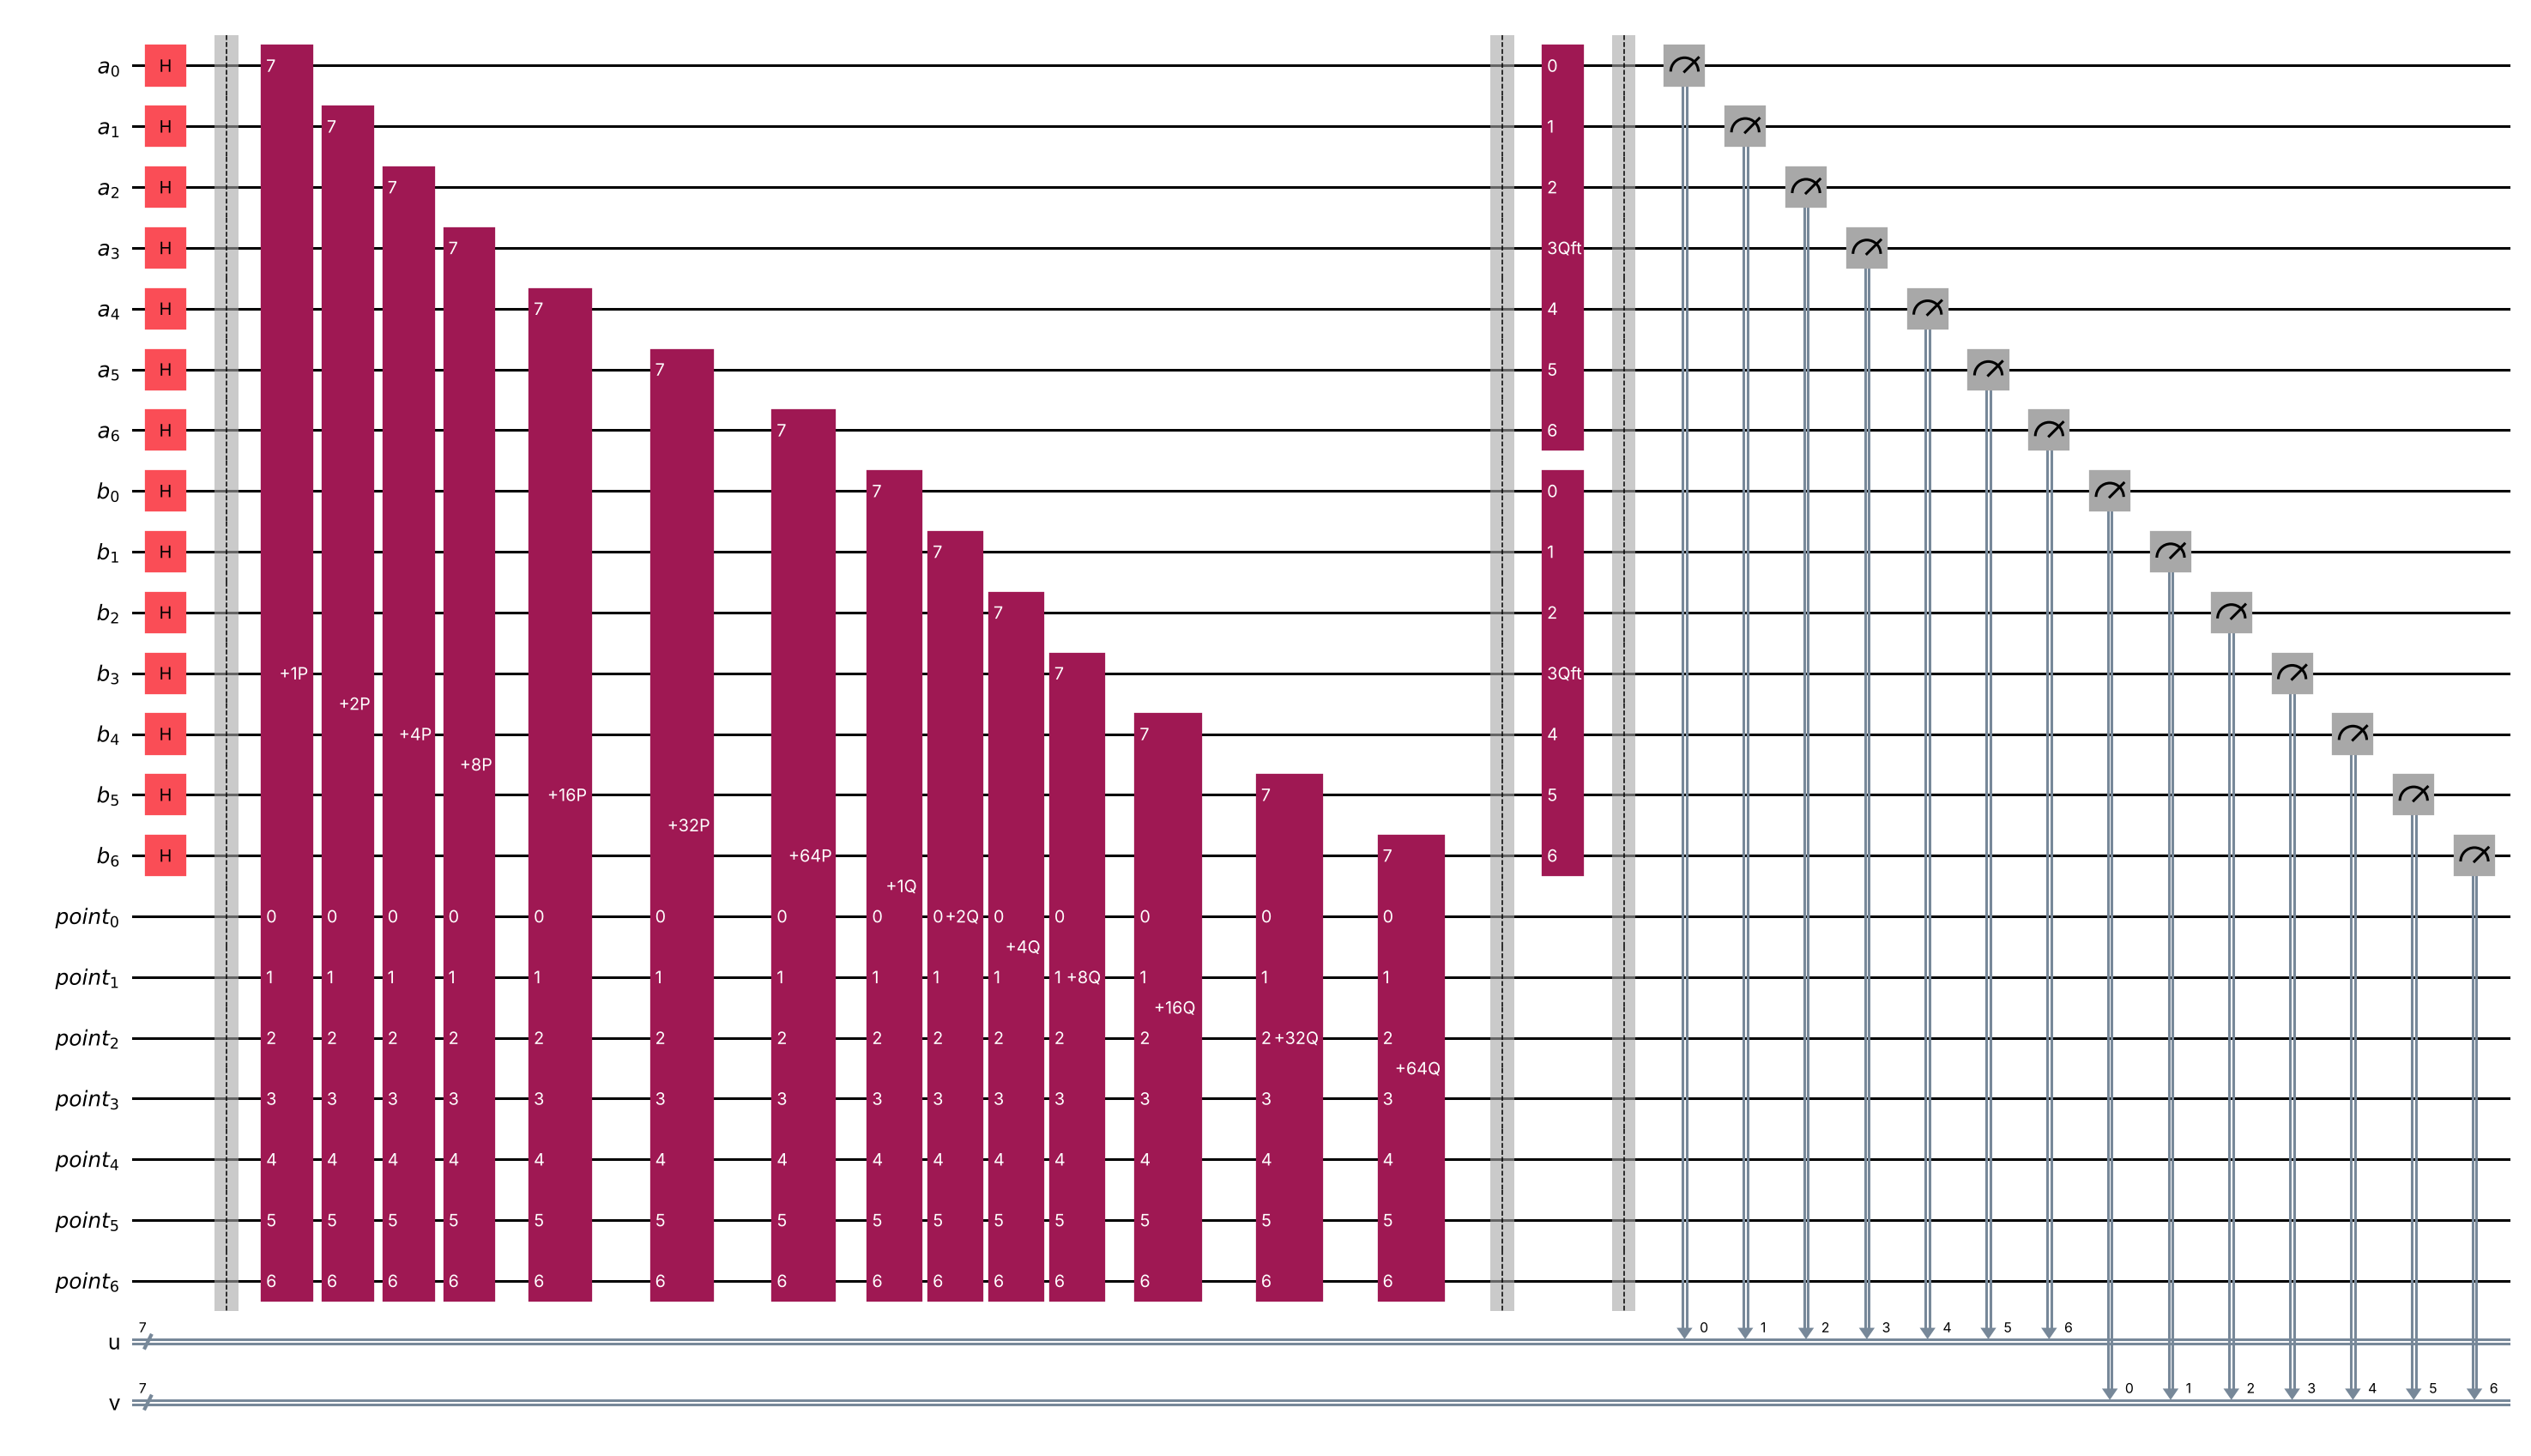

In [10]:
def shor_ecdlp_circuit(P, Q):
    qa, qb, qp = QuantumRegister(m, "a"), QuantumRegister(m, "b"), QuantumRegister(t, "point")
    cu, cv = ClassicalRegister(m, "u"), ClassicalRegister(m, "v")
    qc = QuantumCircuit(qa, qb, qp, cu, cv, name="Shor-ECDLP")

    qc.h(qa)                                   # 1. uniform superposition over a and b
    qc.h(qb)
    qc.barrier()
    qc.compose(ecdlp_oracle(P, Q), qubits=[*qa, *qb, *qp], inplace=True)   # 2. |a,b,O> -> |a,b,aP+bQ>
    qc.barrier()
    qc.append(QFTGate(m), qa)                  # 3. QFT on both exponent registers
    qc.append(QFTGate(m), qb)
    qc.barrier()
    qc.measure(qa, cu)                         # 4. measure (u, v)
    qc.measure(qb, cv)
    return qc

qc = shor_ecdlp_circuit(P, Q)
print(f"{qc.num_qubits} qubits, {qc.num_clbits} classical bits")
qc.draw("mpl", fold=-1, scale=0.55)

## 5. Run it on the Aer simulator

In [11]:
tqc = transpile(qc, sim)
print("transpiled gate counts:", dict(tqc.count_ops()))

shots = 4096
result = sim.run(tqc, shots=shots, seed_simulator=2026).result()
counts = result.get_counts()

def parse(key):
    # Qiskit prints the last-added register first: key = "<v bits> <u bits>"
    v_bits, u_bits = key.split()
    return int(u_bits, 2), int(v_bits, 2)

uv_counts = Counter()
for key, c in counts.items():
    uv_counts[parse(key)] += c

print(f"{len(uv_counts)} distinct (u, v) outcomes out of {N*N} possible")
print("most frequent:", uv_counts.most_common(8))

transpiled gate counts: {'cp': 42, 'h': 28, 'unitary': 14, 'measure': 14, 'barrier': 3}


976 distinct (u, v) outcomes out of 16384 possible
most frequent: [((0, 0), 40), ((108, 12), 37), ((15, 119), 34), ((99, 120), 34), ((34, 5), 33), ((118, 6), 32), ((104, 117), 32), ((20, 116), 32)]


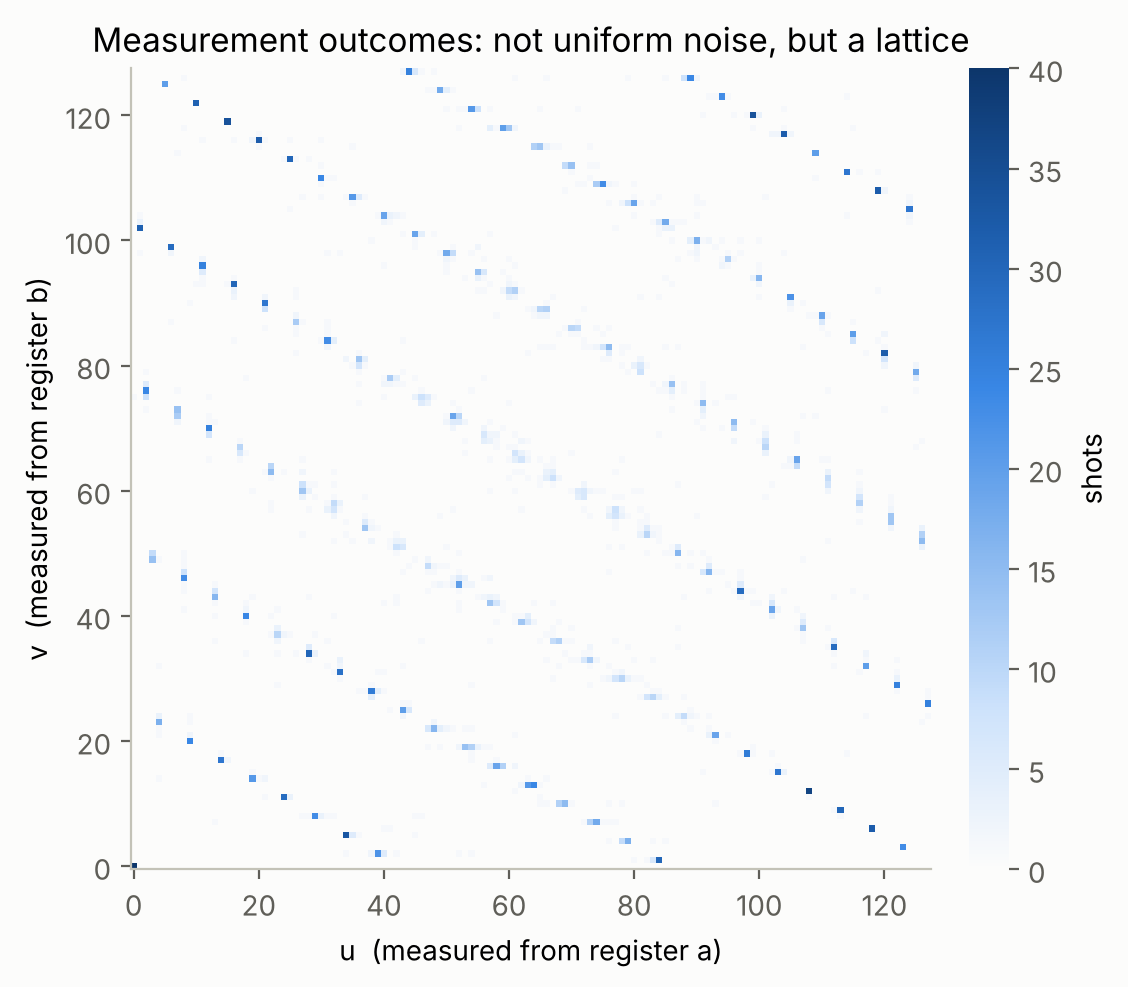

In [12]:
H = np.zeros((N, N))
for (u, v), c in uv_counts.items():
    H[v, u] = c

fig, ax = plt.subplots(figsize=(6, 5.2))
im = ax.imshow(H, origin="lower", cmap=SEQ_BLUE, interpolation="nearest", extent=(-0.5, N - 0.5, -0.5, N - 0.5))
cb = fig.colorbar(im, ax=ax, fraction=0.046, pad=0.04)
cb.set_label("shots")
cb.outline.set_visible(False)
ax.set(xlabel="u  (measured from register a)", ylabel="v  (measured from register b)",
       title="Measurement outcomes: not uniform noise, but a lattice")
plt.show()

The outcomes concentrate on a lattice of roughly 127 spots: the **dual lattice** $L^\perp = \{(u,v): v \equiv ku \pmod{127}\}$, rescaled from $\mathbb{Z}_{127}$ to the 128-point register. Each spot already encodes $k$.

## 6. Classical post-processing: $(u, v) \to k$

With an ideal QFT over $\mathbb{Z}_{127}$ we would get $v \equiv ku$ exactly. Our registers have $N = 128$, so $u \approx N j / n$ and $v \approx N l / n$ with $l \equiv kj \pmod n$. For each shot:

1. rescale: $u \cdot n/N$ and $v \cdot n/N$, and take floor and ceiling of each (absorbs the 128-vs-127 mismatch)
2. skip $j = 0$ (no information about $k$)
3. candidate $k = l \cdot j^{-1} \bmod n$
4. **verify** classically: does $kP = Q$? This check is cheap and uses only public data.

In [13]:
def candidates_from(u, v):
    x, y = u * n / N, v * n / N
    cands = set()
    for j in {floor(x) % n, ceil(x) % n}:
        if j == 0:
            continue
        j_inv = pow(j, -1, n)
        for l in {floor(y) % n, ceil(y) % n}:
            cands.add(l * j_inv % n)
    return cands

votes = Counter()
shots_with_verified_k = 0
for (u, v), c in uv_counts.items():
    cands = candidates_from(u, v)
    for kc in cands:
        votes[kc] += c
    if any(ec_mul(kc, P) == Q for kc in cands):
        shots_with_verified_k += c

print(f"shots whose candidates include a key passing kP == Q: {shots_with_verified_k}/{shots} "
      f"({100 * shots_with_verified_k / shots:.1f}%)")
print("top candidates by vote:", votes.most_common(6))

shots whose candidates include a key passing kP == Q: 3284/4096 (80.2%)
top candidates by vote: [(101, 3284), (79, 188), (93, 177), (17, 157), (10, 157), (55, 152)]


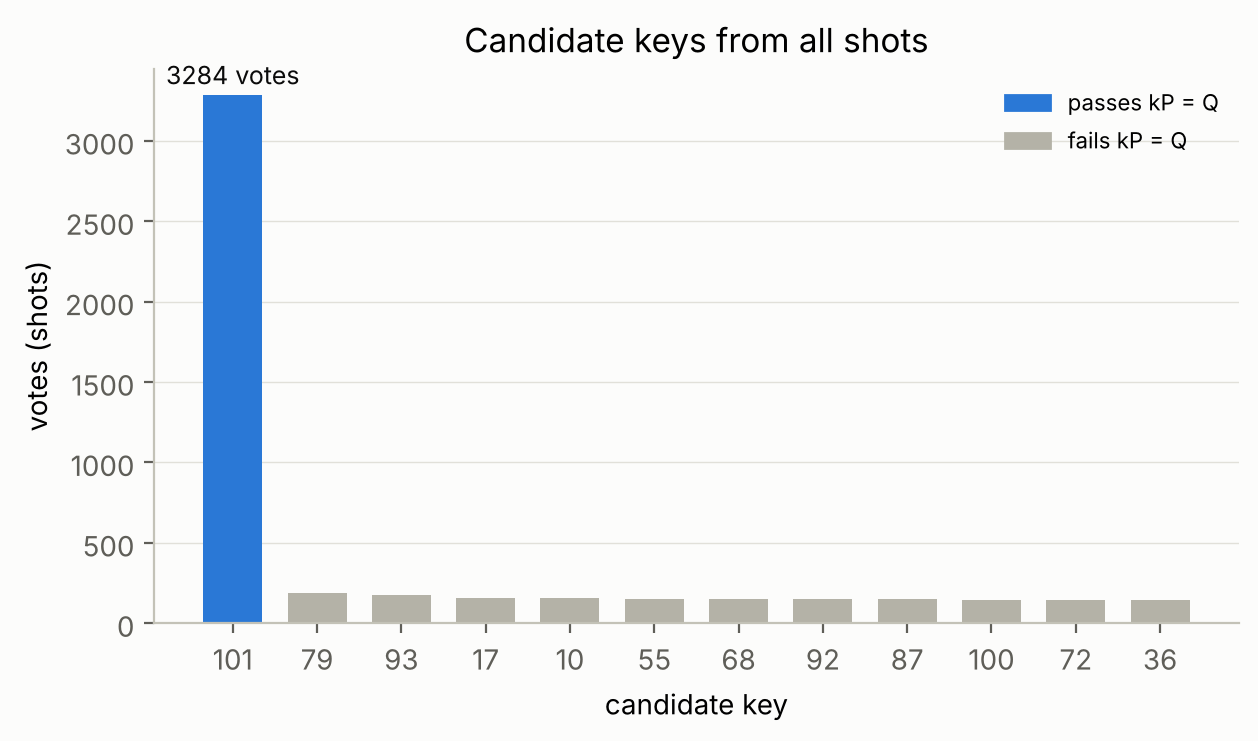

In [14]:
top = votes.most_common(12)
ks = [str(kc) for kc, _ in top]
vs = [c for _, c in top]
ok = [ec_mul(kc, P) == Q for kc, _ in top]

fig, ax = plt.subplots(figsize=(7, 3.6))
bars = ax.bar(ks, vs, color=[BLUE if g else GRAY for g in ok], width=0.7, zorder=2)
for b_, c, g in zip(bars, vs, ok):
    if g:
        ax.annotate(f"{c} votes", (b_.get_x() + b_.get_width() / 2, c), xytext=(0, 4),
                    textcoords="offset points", ha="center", color="#0b0b0b", fontsize=9)
ax.set(xlabel="candidate key", ylabel="votes (shots)", title="Candidate keys from all shots")
ax.grid(axis="y", color="#e1e0d9", linewidth=0.5, zorder=0)
from matplotlib.patches import Patch
ax.legend(handles=[Patch(color=BLUE, label="passes kP = Q"), Patch(color=GRAY, label="fails kP = Q")],
          frameon=False, fontsize=8)
plt.show()

**How many runs do you actually need?** Look at individual shots. Most single shots already produce the key.

In [15]:
memory = sim.run(tqc, shots=10, seed_simulator=7, memory=True).result().get_memory()
print(" shot |  (u,  v)  | candidates            | verified k")
print("------+-----------+-----------------------+-----------")
for i, key in enumerate(memory, 1):
    u, v = parse(key)
    cands = sorted(candidates_from(u, v))
    good = [kc for kc in cands if ec_mul(kc, P) == Q]
    print(f" {i:4d} | ({u:3d},{v:3d}) | {str(cands):21s} | {good[0] if good else '-'}")

 shot |  (u,  v)  | candidates            | verified k
------+-----------+-----------------------+-----------
    1 | ( 31, 84) | [7, 15, 79, 101]      | 101
    2 | ( 45,101) | [22, 60, 86, 101]     | 101
    3 | ( 57, 70) | [33, 48, 67, 126]     | -
    4 | ( 16, 93) | [40, 57, 101, 109]    | 101
    5 | ( 65, 63) | [42, 124, 126]        | -
    6 | ( 15,119) | [72, 81, 101, 118]    | 101
    7 | ( 73, 34) | [4, 37, 77, 101]      | 101
    8 | ( 85,103) | [36, 52, 55, 101]     | 101
    9 | ( 25,113) | [10, 35, 47, 101]     | 101
   10 | ( 64,115) | [24, 26, 101, 103]    | 101


In [16]:
k_found = next(kc for kc, _ in votes.most_common() if ec_mul(kc, P) == Q)

print(f"Recovered key : k = {k_found} = 0b{k_found:07b}")
print(f"Check         : {k_found}·P = {ec_mul(k_found, P)}  vs  Q = {Q}")
print(f"Secret key    : {k_secret}  ->  {'CRACKED' if k_found == k_secret else 'mismatch'}")

Recovered key : k = 101 = 0b1100101
Check         : 101·P = (41, 27)  vs  Q = (41, 27)
Secret key    : 101  ->  CRACKED


## 7. Packaged attack: crack fresh random 7-bit keys

Everything above, wrapped into one function that receives only the public key $Q$.

In [17]:
def shor_crack(P, Q, shots=1024, seed=None):
    # public inputs only: curve, n, P, Q
    tqc = transpile(shor_ecdlp_circuit(P, Q), sim)
    counts = sim.run(tqc, shots=shots, seed_simulator=seed).result().get_counts()
    votes = Counter()
    for key, c in counts.items():
        for kc in candidates_from(*parse(key)):
            votes[kc] += c
    for kc, _ in votes.most_common():
        if ec_mul(kc, P) == Q:
            return kc
    return None

rng = np.random.default_rng(42)
for trial in range(3):
    k_test = int(rng.integers(64, n))          # random 7-bit key in [64, 126]
    Q_test = ec_mul(k_test, P)
    k_hat = shor_crack(P, Q_test, seed=trial)
    print(f"secret {k_test:3d} (0b{k_test:07b})  Q = {Q_test}  ->  Shor found {k_hat}  {'OK' if k_hat == k_test else 'FAIL'}")

secret  69 (0b1000101)  Q = (124, 19)  ->  Shor found 69  OK


secret 112 (0b1110000)  Q = (99, 36)  ->  Shor found 112  OK


secret 105 (0b1101001)  Q = (106, 115)  ->  Shor found 105  OK


## Summary

* **Reduction.** $Q = kP$ turns $f(a,b) = aP + bQ$ into $(a + kb)P$, a function on $\mathbb{Z}_n^2$ that is periodic along the hidden vector $(-k, 1)$. Unlike factoring, the period is two-dimensional.
* **Quantum step.** Superpose $(a,b)$, compute $f$ coherently with 14 controlled point-additions, and QFT both registers. The measurement lands on the dual lattice $v \equiv ku \pmod n$.
* **Classical step.** One good shot gives $k = v\,u^{-1} \bmod n$, and $kP = Q$ confirms it. Here roughly 80% of single shots yield the key.

**Honest caveats for discussion**
* The controlled point-additions are compiled as $2^8 \times 2^8$ permutation unitaries over a 7-qubit index encoding of the 127 points. That is fine for simulation, and it uses only public data ($P$, $Q$), never $k$. At cryptographic sizes the oracle must instead be built from reversible modular arithmetic on the $(x, y)$ coordinates. Roetteler et al. (2017) estimate about $9n + 2\lceil\log_2 n\rceil + 10$ logical qubits for an $n$-bit curve, about 2,330 for 256-bit curves.
* The simulator is noiseless. On real hardware, each 8-qubit permutation would decompose into a very large number of two-qubit gates.
* $N = 128$ vs $n = 127$ is a lucky near-match. For a group order far from a power of two, use larger registers (more QFT precision) and continued-fraction / lattice post-processing.